In [1]:
from google.colab import drive
import zipfile

drive.mount('/content/drive')
ZIP_FILE_PATH = '/content/drive/MyDrive/DS Project/Copy of bbdd_kidney.zip'
EXTRACT_DIR = '/content/dataset'
with zipfile.ZipFile(ZIP_FILE_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

Mounted at /content/drive


In [5]:
import os
import glob
import numpy as np
from PIL import Image, ImageFile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

ImageFile.LOAD_TRUNCATED_IMAGES = True


class KidneyDataset(Dataset):
    def __init__(self, image_paths, labels, mean, std):
        self.image_paths = image_paths
        self.labels = labels
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")
        img_tensor = TF.to_tensor(img)

        dtype, device = img_tensor.dtype, img_tensor.device
        mean_tensor = torch.as_tensor(self.mean, dtype=dtype, device=device)
        std_tensor = torch.as_tensor(self.std, dtype=dtype, device=device)
        norm_img = (img_tensor - mean_tensor[:, None, None]) / std_tensor[:, None, None]
        label = self.labels[idx]
        return {
            "image": norm_img,
            "label": torch.tensor(label, dtype=torch.long)
        }


def extract_all_labels(image_paths, labels_dir):
    labels = []
    for img_path in image_paths:
        file_stem = os.path.splitext(os.path.basename(img_path))[0]
        txt_path = os.path.join(labels_dir, f"{file_stem}.txt")
        if not os.path.exists(txt_path):
            raise FileNotFoundError(f"Missing label file for image '{os.path.basename(img_path)}'. Expected at: {txt_path}")
        with open(txt_path, 'r') as f:
            _ = f.readline()
            diag_line = f.readline()
            label_int = int(diag_line.split('Global diagnosis: ')[-1].split('\n')[0])
            labels.append(label_int)
    return labels


def pad_collate_fn(batch):
    images = [item["image"] for item in batch]
    labels = [item["label"] for item in batch]

    max_h = max(img.shape[1] for img in images)
    max_w = max(img.shape[2] for img in images)

    padded_images = []
    for img in images:
        c, h, w = img.shape
        pad_h = max_h - h
        pad_w = max_w - w
        padded_img = F.pad(img, (0, pad_w, 0, pad_h), value=0.0)
        padded_images.append(padded_img)

    padded_images = torch.stack(padded_images, dim=0)
    labels = torch.tensor(labels, dtype=torch.long)

    return {"image": padded_images, "label": labels}


def compute_dataset_stats(train_paths):
    print("Computing mean and std for training set...")
    mean = torch.zeros(3)
    std = torch.zeros(3)

    for path in train_paths:
        img = Image.open(path).convert("RGB")
        tensor = TF.to_tensor(img)
        mean += tensor.mean(dim=(1, 2))
        std += tensor.std(dim=(1, 2))

    mean /= len(train_paths)
    std /= len(train_paths)

    print(f"Calculated Mean: {mean.tolist()}")
    print(f"Calculated Std:  {std.tolist()}")
    return mean.tolist(), std.tolist()


def build_efficientnet_model(num_classes=2):
    model = timm.create_model("efficientnet_b0", pretrained=True, in_chans=3)
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )
    return model

def evaluate_auc(model, dataloader, device):
    model.eval()
    all_targets, all_probs = [], []

    with torch.no_grad():
        for batch in dataloader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)[:, 1]
            all_targets.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    auc_score = roc_auc_score(all_targets, all_probs)
    return auc_score, np.array(all_targets), np.array(all_probs)


def run_pipeline():
    IMAGES_DIR = "dataset/images"
    LABELS_DIR = "dataset/labels"
    BATCH_SIZE = 16
    EPOCHS = 12
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    image_paths = sorted(glob.glob(os.path.join(IMAGES_DIR, "*.jpg")))

    all_labels = extract_all_labels(image_paths, LABELS_DIR)
    train_val_files, test_files, train_val_labels, test_labels = train_test_split(
        image_paths,
        all_labels,
        test_size=0.20,
        stratify=all_labels,
        random_state=42)

    train_files, val_files, train_labels, val_labels = train_test_split(
        train_val_files,
        train_val_labels,
        test_size=0.20,
        stratify=train_val_labels,
        random_state=42)

    mean, std = compute_dataset_stats(train_files)
    train_ds = KidneyDataset(train_files, train_labels, mean, std)
    val_ds   = KidneyDataset(val_files, val_labels, mean, std)
    test_ds  = KidneyDataset(test_files, test_labels, mean, std)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=pad_collate_fn)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)
    test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)

    model = build_efficientnet_model(num_classes=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
    criterion = nn.CrossEntropyLoss()

    best_val_auc = 0.0

    print("Training EfficientNet-B0...")
    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0

        for batch in train_loader:
            images = batch["image"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
        val_auc, _, _ = evaluate_auc(model, val_loader, DEVICE)

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            torch.save(model.state_dict(), "best_efficientnet.pth")

        print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] - Loss: {running_loss/len(train_ds):.4f} | Val ROC-AUC: {val_auc:.4f}")

    print("\nEvaluating on Unseen Test Set...")
    model.load_state_dict(torch.load("best_efficientnet.pth"))

    test_auc, y_true, y_probs = evaluate_auc(model, test_loader, DEVICE)
    print(f"FINAL HOLDOUT TEST ROC-AUC: {test_auc:.4f}")

    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Test ROC Curve (AUC = {test_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Test Set ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig("test_roc_curve.png", dpi=300)
    plt.close()

if __name__ == "__main__":
    run_pipeline()

Computing mean and std for training set...
Calculated Mean: [0.10081415623426437, 0.10056057572364807, 0.10157609730958939]
Calculated Std:  [0.17345009744167328, 0.17280830442905426, 0.17332030832767487]
Training EfficientNet-B0...
Epoch [01/12] - Loss: 0.5103 | Val ROC-AUC: 0.7726
Epoch [02/12] - Loss: 0.3684 | Val ROC-AUC: 0.8204
Epoch [03/12] - Loss: 0.2123 | Val ROC-AUC: 0.8122
Epoch [04/12] - Loss: 0.0835 | Val ROC-AUC: 0.8454
Epoch [05/12] - Loss: 0.0608 | Val ROC-AUC: 0.8367
Epoch [06/12] - Loss: 0.0214 | Val ROC-AUC: 0.8349
Epoch [07/12] - Loss: 0.0218 | Val ROC-AUC: 0.8157
Epoch [08/12] - Loss: 0.0298 | Val ROC-AUC: 0.8444
Epoch [09/12] - Loss: 0.0294 | Val ROC-AUC: 0.8330
Epoch [10/12] - Loss: 0.0105 | Val ROC-AUC: 0.8470
Epoch [11/12] - Loss: 0.0059 | Val ROC-AUC: 0.8426
Epoch [12/12] - Loss: 0.0264 | Val ROC-AUC: 0.8293

Evaluating on Unseen Test Set...
FINAL HOLDOUT TEST ROC-AUC: 0.8276


Slower learning rate, adding a schedular, increased model regulation

In [4]:
def build_efficientnet_model(num_classes=2):
    model = timm.create_model("efficientnet_b0", pretrained=True, in_chans=3)
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
    return model

def run_pipeline():
    IMAGES_DIR = "dataset/images"
    LABELS_DIR = "dataset/labels"
    BATCH_SIZE = 16
    EPOCHS = 12
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    image_paths = sorted(glob.glob(os.path.join(IMAGES_DIR, "*.jpg")))

    all_labels = extract_all_labels(image_paths, LABELS_DIR)
    train_val_files, test_files, train_val_labels, test_labels = train_test_split(
        image_paths,
        all_labels,
        test_size=0.20,
        stratify=all_labels,
        random_state=42)

    train_files, val_files, train_labels, val_labels = train_test_split(
        train_val_files,
        train_val_labels,
        test_size=0.20,
        stratify=train_val_labels,
        random_state=42)

    mean, std = compute_dataset_stats(train_files)
    train_ds = KidneyDataset(train_files, train_labels, mean, std)
    val_ds   = KidneyDataset(val_files, val_labels, mean, std)
    test_ds  = KidneyDataset(test_files, test_labels, mean, std)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=pad_collate_fn)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)
    test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)

    model = build_efficientnet_model(num_classes=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=3e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=12, eta_min=1e-6)
    criterion = nn.CrossEntropyLoss()

    best_val_auc = 0.0

    print("Training EfficientNet-B0...")
    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0

        for batch in train_loader:
            images = batch["image"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
        scheduler.step()
        val_auc, _, _ = evaluate_auc(model, val_loader, DEVICE)

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            torch.save(model.state_dict(), "best_efficientnet.pth")

        print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] - Loss: {running_loss/len(train_ds):.4f} | Val ROC-AUC: {val_auc:.4f}")

    print("\nEvaluating on Unseen Test Set...")
    model.load_state_dict(torch.load("best_efficientnet.pth"))

    test_auc, y_true, y_probs = evaluate_auc(model, test_loader, DEVICE)
    print(f"FINAL HOLDOUT TEST ROC-AUC: {test_auc:.4f}")

    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Test ROC Curve (AUC = {test_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Test Set ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig("test_roc_curve.png", dpi=300)
    plt.close()

if __name__ == "__main__":
    run_pipeline()

Computing mean and std for training set...
Calculated Mean: [0.10081415623426437, 0.10056057572364807, 0.10157609730958939]
Calculated Std:  [0.17345009744167328, 0.17280830442905426, 0.17332030832767487]
Training EfficientNet-B0...
Epoch [01/12] - Loss: 0.5524 | Val ROC-AUC: 0.6673
Epoch [02/12] - Loss: 0.4647 | Val ROC-AUC: 0.7501
Epoch [03/12] - Loss: 0.4042 | Val ROC-AUC: 0.7873
Epoch [04/12] - Loss: 0.3123 | Val ROC-AUC: 0.8106
Epoch [05/12] - Loss: 0.2294 | Val ROC-AUC: 0.8032
Epoch [06/12] - Loss: 0.1494 | Val ROC-AUC: 0.7907
Epoch [07/12] - Loss: 0.1110 | Val ROC-AUC: 0.7919
Epoch [08/12] - Loss: 0.0782 | Val ROC-AUC: 0.7800
Epoch [09/12] - Loss: 0.0545 | Val ROC-AUC: 0.7790
Epoch [10/12] - Loss: 0.0440 | Val ROC-AUC: 0.7798
Epoch [11/12] - Loss: 0.0386 | Val ROC-AUC: 0.7816
Epoch [12/12] - Loss: 0.0389 | Val ROC-AUC: 0.7738

Evaluating on Unseen Test Set...
FINAL HOLDOUT TEST ROC-AUC: 0.8008


Did not perform better then a model with higher lr, no schedular, and smaller regularization.

Add MONAI Transforms

In [2]:
!pip install monai nibabel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 45.3 MB/s eta 0:00:00


In [7]:
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    ScaleIntensityRangePercentilesd,
    RandRotated,
    RandAdjustContrastd,
    RandGaussianNoised,
    EnsureTyped,
)
import torch

train_transforms = Compose([
    LoadImaged(keys=["image"], image_only=True),
    EnsureChannelFirstd(keys=["image"]),
    ScaleIntensityRangePercentilesd(
        keys=["image"], lower=1, upper=99, b_min=0.0, b_max=1.0, clip=True),
    RandRotated(keys=["image"], range_x=0.26, prob=0.5, mode="bilinear"),
    RandAdjustContrastd(keys=["image"], prob=0.4, gamma=(0.8, 1.2)),
    RandGaussianNoised(keys=["image"], prob=0.3, mean=0.0, std=0.05),
    EnsureTyped(keys=["image"], dtype=torch.float32)
])

val_transforms = Compose([
    LoadImaged(keys=["image"], image_only=True),
    EnsureChannelFirstd(keys=["image"]),
    ScaleIntensityRangePercentilesd(
        keys=["image"], lower=1, upper=99, b_min=0.0, b_max=1.0, clip=True),
    EnsureTyped(keys=["image"], dtype=torch.float32)
])


class MONAIKidneyDataset(Dataset):
    def __init__(self, image_paths, labels, transform):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        data_dict = {"image": self.image_paths[idx]}
        data_dict = self.transform(data_dict)

        img_tensor = data_dict["image"]
        if img_tensor.shape[0] == 1:
            img_tensor = img_tensor.repeat(3, 1, 1)

        return {
            "image": img_tensor,
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }


def build_efficientnet_model(num_classes=2):
    model = timm.create_model("efficientnet_b0", pretrained=True, in_chans=3)
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )
    return model


def run_pipeline():
    IMAGES_DIR = "dataset/images"
    LABELS_DIR = "dataset/labels"
    BATCH_SIZE = 16
    EPOCHS = 15
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    image_paths = sorted(glob.glob(os.path.join(IMAGES_DIR, "*.jpg")))

    all_labels = extract_all_labels(image_paths, LABELS_DIR)
    train_val_files, test_files, train_val_labels, test_labels = train_test_split(
        image_paths,
        all_labels,
        test_size=0.20,
        stratify=all_labels,
        random_state=42)

    train_files, val_files, train_labels, val_labels = train_test_split(
        train_val_files,
        train_val_labels,
        test_size=0.20,
        stratify=train_val_labels,
        random_state=42)

    train_ds = MONAIKidneyDataset(train_files, train_labels, transform = train_transforms)
    val_ds   = MONAIKidneyDataset(val_files, val_labels, transform = val_transforms)
    test_ds  = MONAIKidneyDataset(test_files, test_labels, transform = val_transforms)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=pad_collate_fn)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)
    test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate_fn)

    model = build_efficientnet_model(num_classes=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=8, gamma=0.5)
    criterion = nn.CrossEntropyLoss()

    best_val_auc = 0.0

    print("Training EfficientNet-B0...")
    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0

        for batch in train_loader:
            images = batch["image"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
        scheduler.step()
        val_auc, _, _ = evaluate_auc(model, val_loader, DEVICE)

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            torch.save(model.state_dict(), "best_efficientnet.pth")

        print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] - Loss: {running_loss/len(train_ds):.4f} | Val ROC-AUC: {val_auc:.4f}")

    print("\nEvaluating on Unseen Test Set...")
    model.load_state_dict(torch.load("best_efficientnet.pth"))

    test_auc, y_true, y_probs = evaluate_auc(model, test_loader, DEVICE)
    print(f"FINAL HOLDOUT TEST ROC-AUC: {test_auc:.4f}")

    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Test ROC Curve (AUC = {test_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Test Set ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig("test_roc_curve.png", dpi=300)
    plt.close()

if __name__ == "__main__":
    run_pipeline()

Training EfficientNet-B0...
Epoch [01/15] - Loss: 0.5237 | Val ROC-AUC: 0.7377
Epoch [02/15] - Loss: 0.4503 | Val ROC-AUC: 0.7591
Epoch [03/15] - Loss: 0.3920 | Val ROC-AUC: 0.7896
Epoch [04/15] - Loss: 0.3405 | Val ROC-AUC: 0.7880
Epoch [05/15] - Loss: 0.2835 | Val ROC-AUC: 0.7550
Epoch [06/15] - Loss: 0.2312 | Val ROC-AUC: 0.7962
Epoch [07/15] - Loss: 0.2080 | Val ROC-AUC: 0.7795
Epoch [08/15] - Loss: 0.1453 | Val ROC-AUC: 0.7906
Epoch [09/15] - Loss: 0.1095 | Val ROC-AUC: 0.8063
Epoch [10/15] - Loss: 0.0871 | Val ROC-AUC: 0.8218
Epoch [11/15] - Loss: 0.0821 | Val ROC-AUC: 0.8246
Epoch [12/15] - Loss: 0.0747 | Val ROC-AUC: 0.8372
Epoch [13/15] - Loss: 0.0659 | Val ROC-AUC: 0.8456
Epoch [14/15] - Loss: 0.0486 | Val ROC-AUC: 0.8422
Epoch [15/15] - Loss: 0.0683 | Val ROC-AUC: 0.8186

Evaluating on Unseen Test Set...
FINAL HOLDOUT TEST ROC-AUC: 0.8718


In [3]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=8d9d712ebb880ed346dbd79c2e98b706deacbc603f002aa70ba40e6ebbd15fd2
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


In [4]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def generate_ultrasound_gradcam(model, dataset_item, target_class=1, save_path="gradcam_result.png"):
    model.eval()
    device = next(model.parameters()).device
    input_tensor = dataset_item["image"].unsqueeze(0).to(device)
    true_label = dataset_item["label"].item()
    target_layers = [model.conv_head]

    cam = GradCAM(model=model, target_layers=target_layers)
    targets = [ClassifierOutputTarget(target_class)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
    raw_img = input_tensor.squeeze(0).cpu().numpy().transpose(1, 2, 0)
    raw_img = (raw_img - raw_img.min()) / (raw_img.max() - raw_img.min() + 1e-8)

    visualization = show_cam_on_image(raw_img, grayscale_cam, use_rgb=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(raw_img)
    axes[0].set_title(f"Raw Ultrasound Scan (True Label: {true_label})")
    axes[0].axis("off")
    axes[1].imshow(visualization)
    axes[1].set_title(f"Grad-CAM Focus (Target Class: {target_class})")
    axes[1].axis("off")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = build_efficientnet_model(num_classes=2).to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Data Science Project Data/best_efficientnet (1).pth"))

<All keys matched successfully>

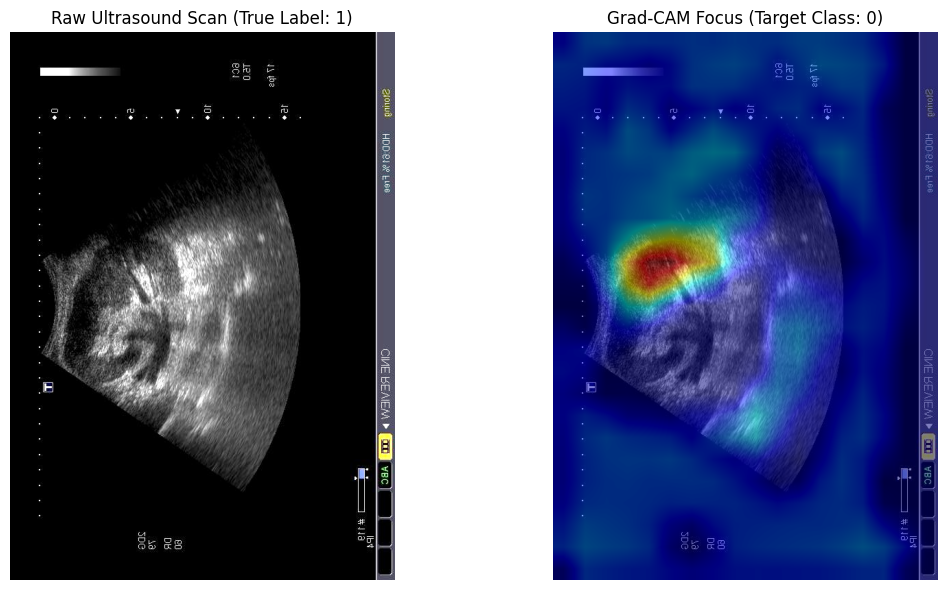

Exception ignored in: <function BaseCAM.__del__ at 0x78e4662caac0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pytorch_grad_cam/base_cam.py", line 221, in __del__
    self.activations_and_grads.release()
  File "/usr/local/lib/python3.13/dist-packages/pytorch_grad_cam/activations_and_gradients.py", line 64, in release
    self.clear()
  File "/usr/local/lib/python3.13/dist-packages/pytorch_grad_cam/activations_and_gradients.py", line 55, in clear
    a.detach_()
  File "/usr/local/lib/python3.13/dist-packages/monai/data/meta_tensor.py", line 336, in __torch_function__
    ret = super().__torch_function__(func, types, args, kwargs)
  File "/usr/local/lib/python3.13/dist-packages/torch/_tensor.py", line 1703, in __torch_function__
    ret = func(*args, **kwargs)
RuntimeError: Can't detach views in-place. Use detach() instead. If you are using DistributedDataParallel (DDP) for training, and gradient_as_bucket_view is set as True, gradients are views 

In [33]:
sample_index = 0
test_sample = test_ds[sample_index]
test_label = test_ds[sample_index]['label'].item()

generate_ultrasound_gradcam(
    model=model,
    dataset_item=test_sample,
    target_class=0,
    save_path="kidney_gradcam_explanation_1.png"
)

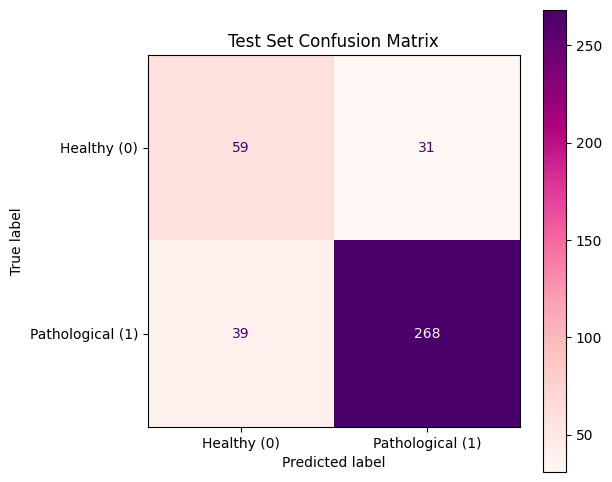

In [29]:
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


def plot_confusion_matrix(model, dataloader, device, class_names=["Normal", "Disease"], save_path="confusion_matrix.png",):
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for batch in dataloader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_targets, all_preds)
    fig, ax = plt.subplots(figsize=(6, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="RdPu", ax=ax, values_format="d")

    plt.title("Test Set Confusion Matrix")
    plt.grid(False)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(model, test_loader, device, class_names=["Healthy (0)", "Pathological (1)"])